In [13]:
import numpy as np

loaded_data = np.load('spiral_data.npz')

# Extract the arrays using the keys defined during export
K = loaded_data['K'].item()
x_train_imported = loaded_data['x']
y_train_imported = loaded_data['y']


In [2]:
%matplotlib inline

In [14]:
%run ./functions.ipynb

In [ ]:
####################################################
#Next make a neural net to find ideal hyper-parameters for us
#{activation function, learning rate, number of hidden layers (capped), size of hidden layers (capped)
#####################################################

In [ ]:
#should be careful with mapping, especially with categorical variable like activation function

In [15]:
%run ./nnFornnHP.ipynb

--- BEGINNING NEURAL ARCHITECTURE SEARCH ---
Starting Neural Architecture Search...
Episode 01 | Reward: 0.3132 | Params: {'activation': 'softmax', 'learning_rate': 0.1, 'num_layers': 3, 'layer_sizes': [8, 4, 4]}
Episode 02 | Reward: 0.3333 | Params: {'activation': 'relu', 'learning_rate': 2.0, 'num_layers': 3, 'layer_sizes': [4, 4, 4]}
Episode 03 | Reward: 0.5266 | Params: {'activation': 'sigmoid', 'learning_rate': 0.5, 'num_layers': 2, 'layer_sizes': [4, 4]}
Episode 04 | Reward: 0.4733 | Params: {'activation': 'softmax', 'learning_rate': 1.0, 'num_layers': 3, 'layer_sizes': [4, 4, 8]}
Episode 05 | Reward: 0.6532 | Params: {'activation': 'relu', 'learning_rate': 0.1, 'num_layers': 2, 'layer_sizes': [4, 4]}
Episode 06 | Reward: 0.6255 | Params: {'activation': 'softmax', 'learning_rate': 2.0, 'num_layers': 2, 'layer_sizes': [8, 4]}
Episode 07 | Reward: 0.4666 | Params: {'activation': 'softmax', 'learning_rate': 1.0, 'num_layers': 3, 'layer_sizes': [4, 4, 4]}
Episode 08 | Reward: 0.9858 

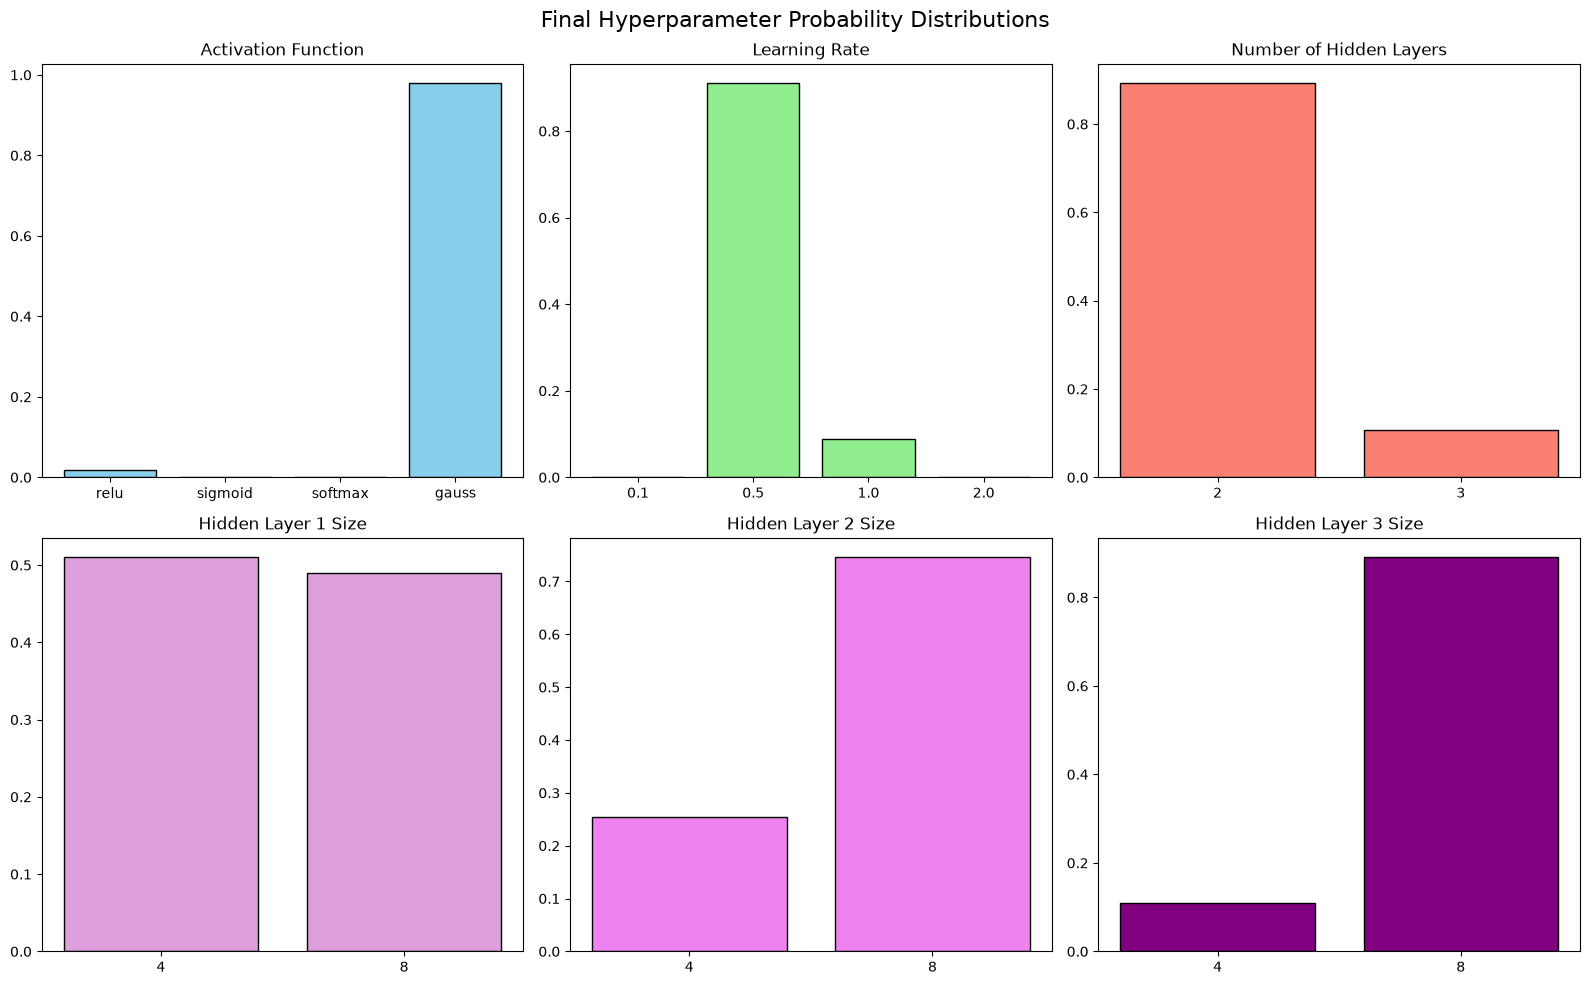

In [17]:
import math
import matplotlib.pyplot as plt

# 1. Define your search bounds here
pos_len = [2, 3]
pos_size = [4, 8]

print("--- BEGINNING NEURAL ARCHITECTURE SEARCH ---")
# 2. Pass the search bounds into the optimizer
nas_search = NASOptimizer(pos_len, pos_size, controller_lr=0.01, beta=0.05, temperature=1.5)

optimal_params, act_probs, lr_probs, layers_probs, size_probs_list = nas_search.optimize(
    x_train, y_train, K, search_episodes=100, N_epochs=1000
)

best_act = optimal_params['activation']
best_lr = optimal_params['learning_rate']
best_layers = optimal_params['num_layers']
mid_size_array = optimal_params['layer_sizes']

print("\n--- TRAINING FINAL MODEL WITH OPTIMAL HYPERPARAMETERS ---")
print(f"Configuration: Act={best_act.upper()}, LR={best_lr}, Layers={best_layers}, Array={mid_size_array}")

# --- Dynamically scaled Plotting Grid ---
max_layers = nas_search.controller.max_layers
total_plots = 3 + max_layers # 3 fixed plots (act, lr, num_layers) + independent sizes

# Define a 3-column grid and calculate how many rows are needed
cols = 3
rows = math.ceil(total_plots / cols)

fig, axs = plt.subplots(rows, cols, figsize=(16, 5 * rows))
fig.suptitle('Final Hyperparameter Probability Distributions', fontsize=16)

# Flatten the axes array so we can iterate through it easily
axs = axs.flatten()

activation_labels = list(nas_search.controller.act_map.values())
lr_labels = [str(v) for v in nas_search.controller.lr_map.values()]
layers_labels = [str(v) for v in nas_search.controller.layers_map.values()]
size_labels = [str(v) for v in nas_search.controller.size_map.values()]

axs[0].bar(activation_labels, act_probs, color='skyblue', edgecolor='black')
axs[0].set_title('Activation Function')

axs[1].bar(lr_labels, lr_probs, color='lightgreen', edgecolor='black')
axs[1].set_title('Learning Rate')

axs[2].bar(layers_labels, layers_probs, color='salmon', edgecolor='black')
axs[2].set_title('Number of Hidden Layers')

# Plot a graph for every potential hidden layer
colors = ['plum', 'violet', 'purple', 'orchid', 'mediumpurple']
for i in range(max_layers):
    c = colors[i % len(colors)]
    axs[3 + i].bar(size_labels, size_probs_list[i], color=c, edgecolor='black')
    axs[3 + i].set_title(f'Hidden Layer {i+1} Size')

# Turn off any empty subplots to keep the image clean
for i in range(total_plots, len(axs)):
    fig.delaxes(axs[i])

plt.tight_layout()
plt.savefig('hyperparameter_distributions.pdf', bbox_inches="tight")
plt.show()

In [ ]:
#test solution

N_epochs = 10000
act = best_params[0]
mid_size_array=best_params[1]
#get model variables
model, x_train_tensor, y_onehot, optimizer, cost_func = setup_model_and_data(x_train, y_train, K, mid_size_array, 1.0, N_epochs, act)

epoch_list    = []
cost_training = []
acc_training  = []

### Train for several epochs: ###
for epoch in range(N_epochs):

    optimizer.zero_grad()
    NN_output = model(x_train_tensor) # Use the tensor returned by your setup function
    cost = cost_func(NN_output, y_onehot)
    cost.backward()
    optimizer.step()

   ### Update the plot and print results every 500 epochs: ###
    if epoch % 500 == 0:
        predicted_class = np.argmax(NN_output.detach().numpy(), axis=1)
        accuracy = np.mean(predicted_class == y_train)

        epoch_list.append(epoch)
        cost_training.append(cost.detach().numpy())
        acc_training.append(accuracy)

        ### Update the plot of the resulting classifier: ###
        fig = plt.figure(2, figsize=(15,8))
        fig.subplots_adjust(hspace=.3, wspace=.3)
        plt.clf()

        updatePlot(model,epoch_list,cost_training,acc_training)

        display.display(plt.gcf())
        print(f"[{act.upper()}] Iteration {epoch}:\n  Training cost {cost:.6f}\n  Training accuracy {accuracy:.6f}\n")

        #Stop clearing the output on the very last step so the final plot stays visible
        if epoch < N_epochs - 500:
            display.clear_output(wait=True)
                    # time.sleep(0.1)

    #
metrics_text = f"Final Cost: {cost:.6f} | Final Accuracy: {accuracy:.6f}"
plt.figtext(0.5, 0.02, metrics_text, ha="center", fontsize=12,
            bbox={"facecolor":"white", "pad":5})

            #Dynamically name the file based on the activation function
filename = f'spiral_results_{act}.pdf'
plt.savefig(filename, bbox_inches="tight")

print(f"Saved {filename}")
print(f"Final {act.upper()} Training cost {cost:.6f}\nFinal {act.upper()} Training accuracy {accuracy:.6f}\n")
print("-" * 50)